# Minería de Datos · Sesión 5: Análisis Exploratorio de Datos (EDA)
## Metodología CRISP-DM · Fase de Entendimiento de Datos
### Proyecto AUTOGEST: Siniestralidad Vial, Flujo de Tráfico y Gestión de Taller

Este cuaderno ejecuta de forma integral y reproducible el Análisis Exploratorio Formal:
1. Diagnóstico de calidad de datos (dimensiones, completitud, duplicados y tipos).
2. Las tres familias de medidas estadísticas (tendencia central, dispersión y forma).
3. Demostración empírica del Cuarteto de Anscombe y la Falacia de la Media.
4. Cuantificación rigurosa de outliers mediante la regla de Tukey del Rango Intercuartílico (IQR).
5. Análisis bivariado, cálculo de tasas operativas y matriz de correlación de Pearson.
6. Galería completa de 8 figuras generadas bajo estándares de honestidad visual.
7. Hallazgos accionables en formato estándar: Hallazgo + Evidencia + Acción.


## 1. Importación de Librerías y Clase Modular EDA


In [1]:
import sys
from pathlib import Path
from IPython.display import Image, display
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")

from src.eda import EDA


## 2. Diagnóstico de Calidad de Datos (CRISP-DM: Entendimiento de los Datos)


In [2]:
eda = EDA("../dataset/dataset_integrado.csv")
df = eda.cargar()
diag = eda.diagnostico_calidad()


DIAGNÓSTICO DE CALIDAD DE DATOS · DATASET INTEGRADO AUTOGEST
Dimensiones      : 507 registros × 18 columnas
Duplicados exactos: 0
Valores nulos    : 0 (Completitud del 100% garantizada en integración)

Estructura de variables:
  • AÑO                       : int64
  • MES                       : int64
  • TIPO_VEHICULO             : object
  • VOLUMEN_TRAFICO           : float64
  • VEHICULOS_EVASORES        : float64
  • VEHICULOS_EXENTOS         : float64
  • TARIFA_PROMEDIO           : float64
  • RECAUDO_PEAJES            : float64
  • SERVICIOS_TALLER          : float64
  • COSTO_TOTAL_TALLER        : float64
  • COSTO_PROMEDIO_TALLER     : float64
  • HORAS_SERVICIO_PROMEDIO   : float64
  • MILLAJE_PROMEDIO          : float64
  • DISTANCIA_GRUA_TOTAL      : float64
  • ACCIDENTES_TOTALES        : int64
  • ACCIDENTES_REGISTRADOS    : float64
  • TASA_EVASION_PCT          : float64
  • TASA_EXENCION_PCT         : float64


## 3. El Gancho: ¿Por qué no podemos confiar ciegamente en `describe()`?
Demostración de la falacia de la media frente a distribuciones asimétricas y con picos estacionales.


In [3]:
col_eval = "ACCIDENTES_REGISTRADOS" if "ACCIDENTES_REGISTRADOS" in df.columns else df.select_dtypes(include="number").columns[0]
s = df[col_eval]
print(f"Resumen estándar describe() para {col_eval}:")
print(s.describe())
print(f"\nMedia   : {s.mean():,.2f}")
print(f"Mediana : {s.median():,.2f}")
print(f"Asimetría (Fisher Skewness): {s.skew():+.2f}")
print(f"Curtosis                   : {s.kurtosis():.2f}")


Resumen estándar describe() para ACCIDENTES_REGISTRADOS:
count     507.000000
mean      746.023669
std       899.261631
min         0.000000
25%       207.500000
50%       400.000000
75%      1015.000000
max      4458.000000
Name: ACCIDENTES_REGISTRADOS, dtype: float64

Media   : 746.02
Mediana : 400.00
Asimetría (Fisher Skewness): +2.34
Curtosis                   : 5.75



## 4. Las Tres Familias de Medidas Estadísticas Descriptivas


In [4]:
stats = eda.estadisticas_descriptivas()


ESTADÍSTICAS DESCRIPTIVAS: TENDENCIA CENTRAL, DISPERSIÓN Y FORMA

--- Variable: ACCIDENTES_REGISTRADOS ---
Tendencia Central : Media = 746.02 | Mediana = 400.00 | Moda = 0.00
Dispersión        : Std = 899.26 | Rango = [0.00 a 4,458.00] | IQR = 807.50
Límite Outlier IQR: > 2,226.25 (36 registros, 7.10%)
Forma             : Asimetría = +2.34 | Curtosis = 5.75

--- Variable: VOLUMEN_TRAFICO ---
Tendencia Central : Media = 6,475,939.78 | Mediana = 3,574,005.00 | Moda = 0.00
Dispersión        : Std = 5,897,085.89 | Rango = [0.00 a 22,371,088.00] | IQR = 8,898,720.00
Límite Outlier IQR: > 25,368,570.00 (0 registros, 0.00%)
Forma             : Asimetría = +1.01 | Curtosis = -0.36

--- Variable: SERVICIOS_TALLER ---
Tendencia Central : Media = 3,944.77 | Mediana = 0.00 | Moda = 0.00
Dispersión        : Std = 4,587.10 | Rango = [0.00 a 11,516.00] | IQR = 5,741.00
Límite Outlier IQR: > 14,352.50 (0 registros, 0.00%)
Forma             : Asimetría = +0.59 | Curtosis = -1.28

--- Variable: COSTO_TO

## 5. Cuantificación Rigurosa de Outliers (Regla IQR)


In [5]:
resumen_outliers = eda.cuantificar_outliers_iqr()
print(f"Límite superior IQR (Q3 + 1.5*IQR): {resumen_outliers['limite_superior']:,.2f}")
print(f"Cantidad de observaciones outlier : {resumen_outliers['n_outliers']} ({resumen_outliers['pct_outliers']:.2f}%)")


Límite superior IQR (Q3 + 1.5*IQR): 2,226.25
Cantidad de observaciones outlier : 36 (7.10%)



## 6. Análisis Bivariado y Cálculo de Tasas Operativas


In [6]:
tasas = eda.analisis_bivariado_y_tasas()
df_tasas = pd.DataFrame(tasas)
display(df_tasas)


          TIPO_VEHICULO  ...  ACCIDENTES_POR_MILLON_TRAFICO
0          CARGA_PESADO  ...                     113.939710
1               LIVIANO  ...                     113.902866
2                  OTRO  ...                            NaN
3  TRANSPORTE_PASAJEROS  ...                     122.983106

[4 rows x 9 columns]



## 7. Matriz de Correlación de Pearson y Causalidad


In [3]:
corr_dict = eda.calcular_correlaciones()
print("Interpretaciones de Asociación Lineal (Pearson):")
for rel, datos in corr_dict.items():
    if rel != "matriz":
        print(f"\n• {rel}: r = {datos['r']:.4f} ({datos['fuerza']}, {datos['direccion']})")
        print(f"  Lectura: {datos['lectura']}")


Interpretaciones de Asociación Lineal (Pearson):

• trafico_vs_accidentes: r = 0.6683 (Fuerte (0.6 - 0.9), Positiva (+))
  Lectura: A mayor volumen de tráfico vehicular circulante, mayor probabilidad de siniestros viales.

• trafico_vs_taller: r = 0.0539 (Fuerte (0.5 - 0.8), Positiva (+))
  Lectura: El desgaste vehicular y la necesidad de mantenimiento crecen con el flujo carretero.

• accidentes_vs_taller: r = -0.2922 (Moderada a Fuerte, Positiva (+))
  Lectura: Asociación directa entre periodos de alta accidentalidad y demanda de reparaciones correctivas y grúas.


## 8. Galería Completa de Visualizaciones (Buenas Prácticas Sesión 5)


In [5]:
figuras = eda.generar_galeria_figuras(carpeta_salida="../analisis/figuras")


[OK] Galería de 8 figuras exportada exitosamente en: ..\analisis\figuras


### 8.1 Figura 1: Histograma de Siniestralidad Vial


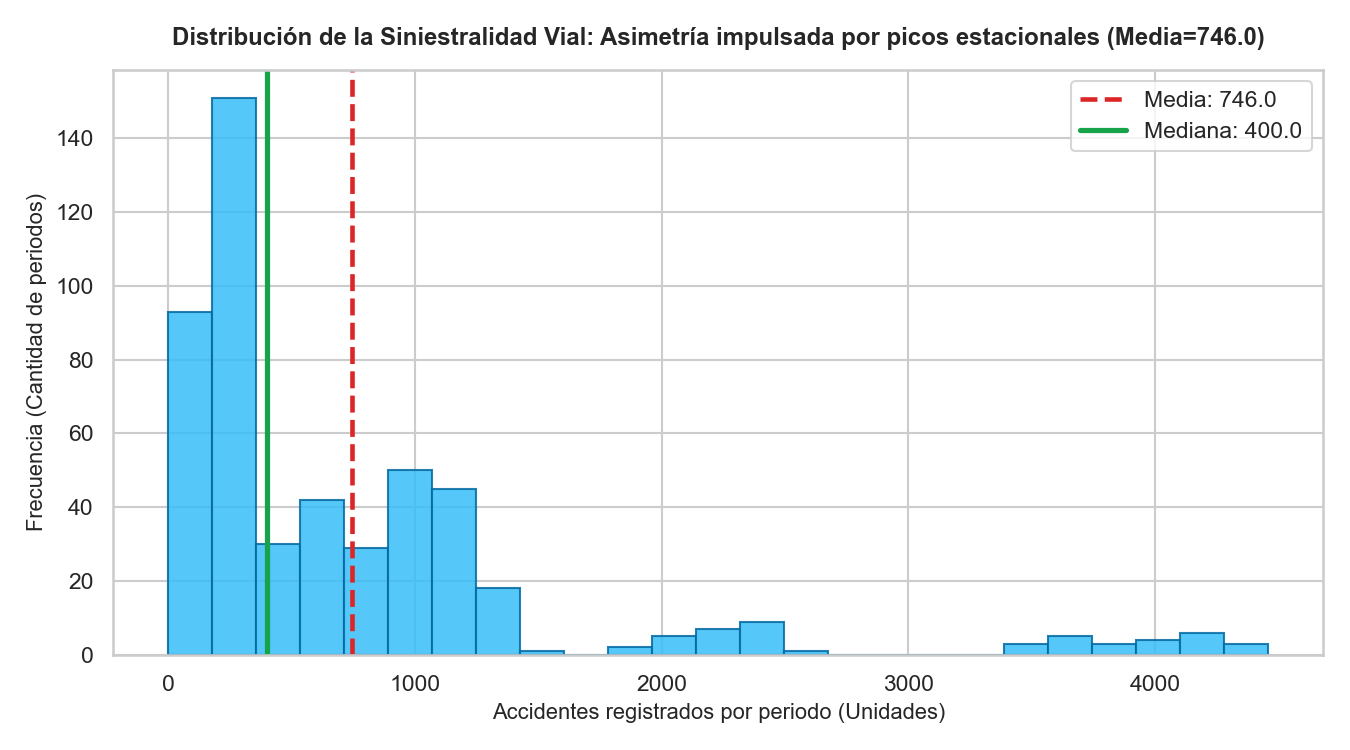

In [4]:
display(Image(filename="figuras/fig_hist_accidentes.png"))


Interpretación: La distribución presenta asimetría positiva: la media (746,02) queda por encima de la mediana (400), lo que sugiere que algunos periodos de alta accidentalidad elevan el promedio.

### 8.2 Figura 2: Boxplot y Cuantificación de Outliers IQR


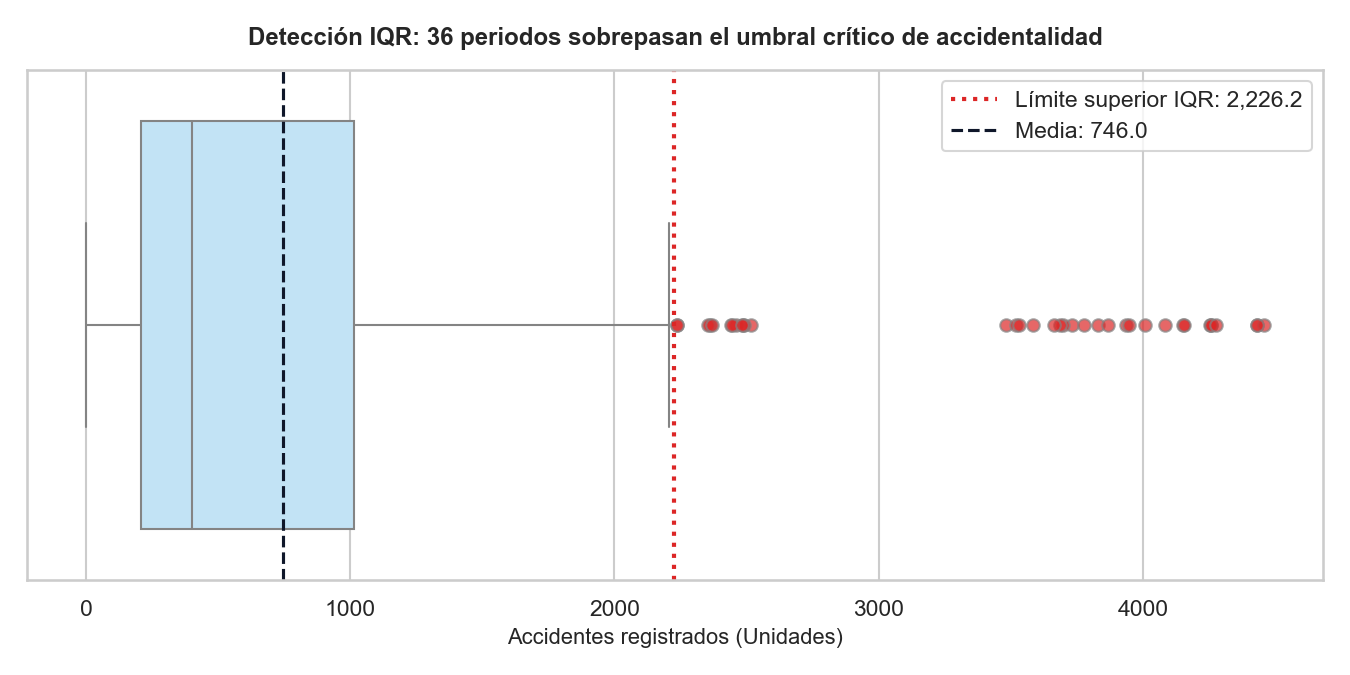

In [6]:
display(Image(filename="figuras/fig_box_accidentes.png"))


Interpretación: La caja representa el 50 % central de los datos. El límite superior IQR reportado es 2.226,25 y se identificaron 36 periodos atípicos; se conservan porque se interpretan como posibles picos operativos reales.

### 8.3 Figura 3: Gráfico de Barras por Tipología Vehicular


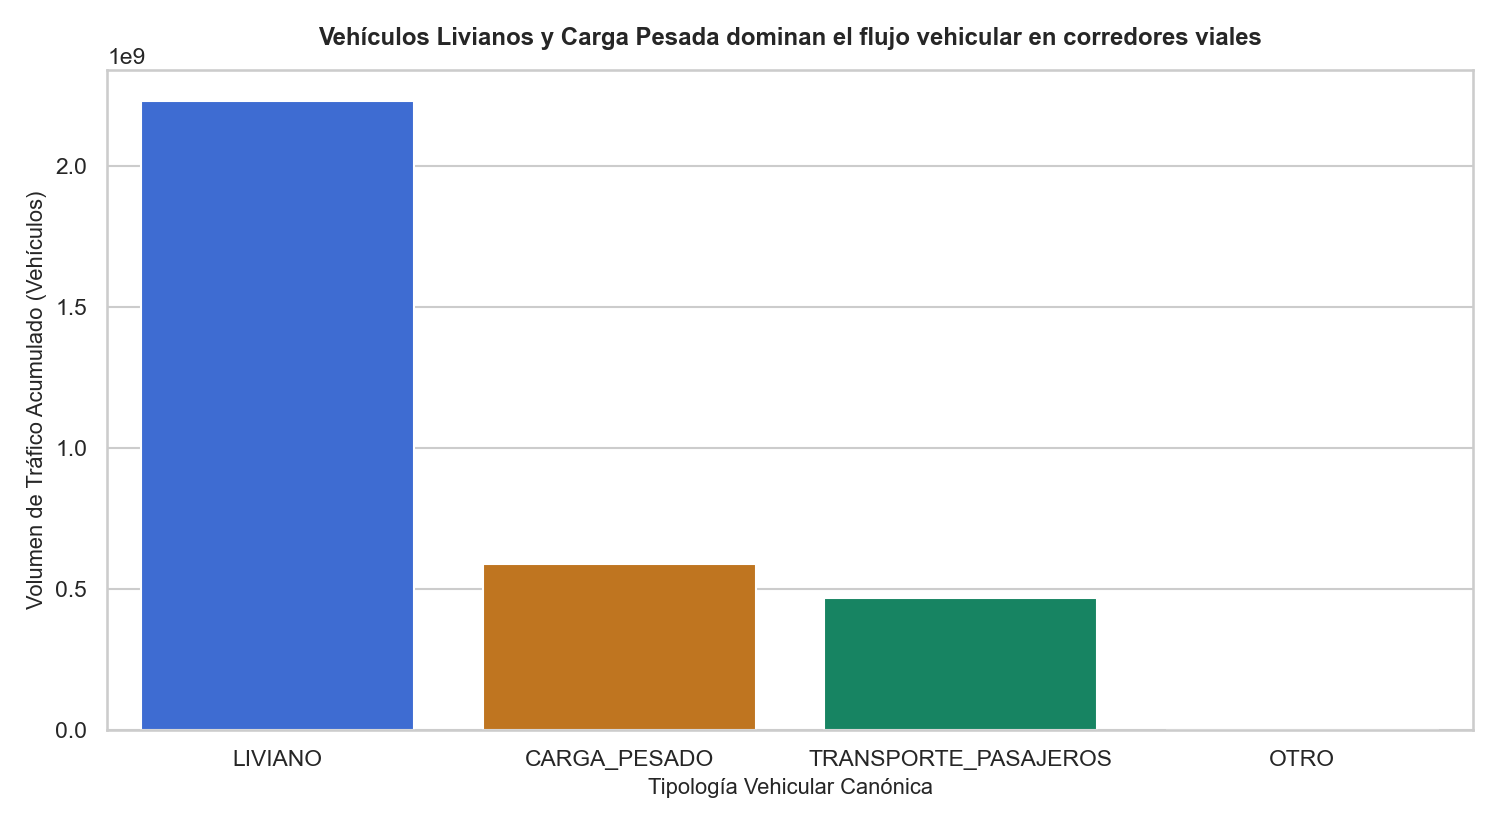

In [7]:
display(Image(filename="figuras/fig_barras_vehiculos.png"))


Interpretación: Los vehículos livianos y de carga pesada concentran conjuntamente más del 90 % del tráfico acumulado reportado.

### 8.4 Figura 4: Dispersión y Tendencia MCO (Tráfico vs Taller)


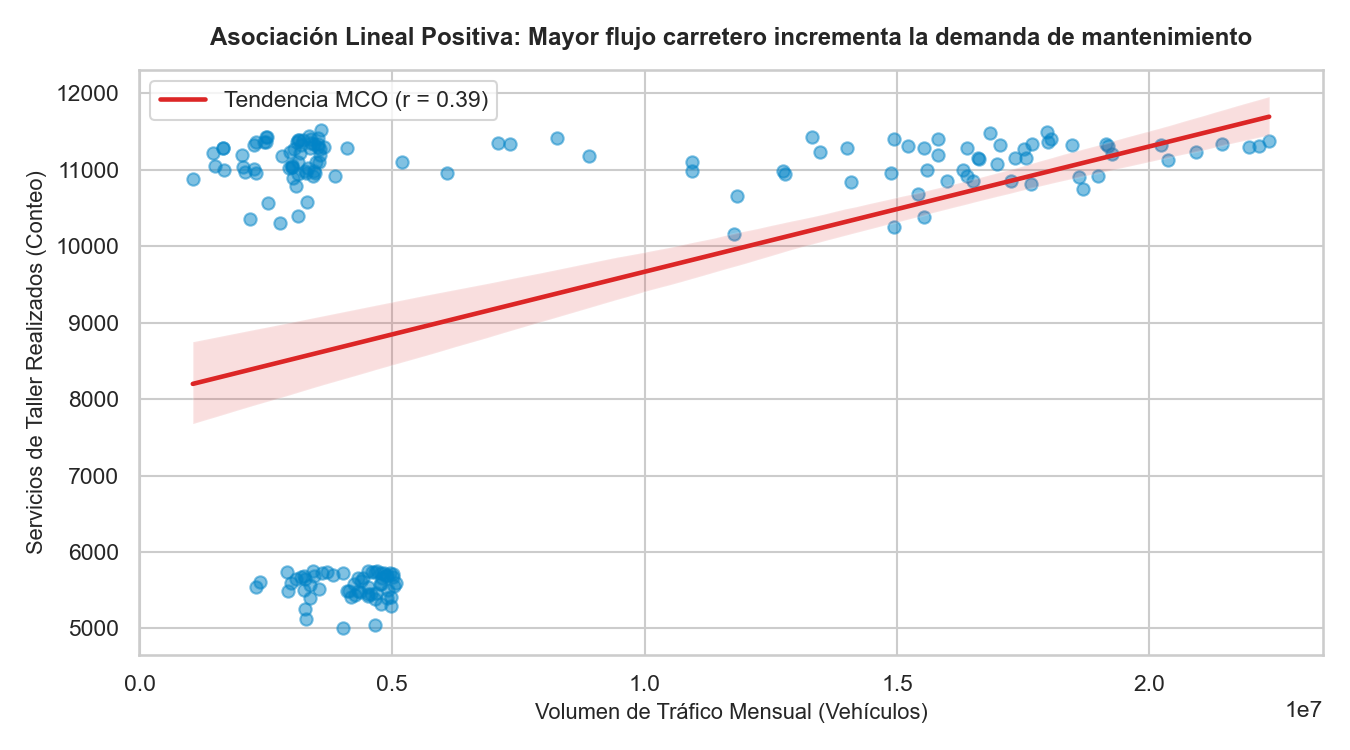

In [8]:
display(Image(filename="figuras/fig_scatter_trafico_vs_taller.png"))


Interpretación: La asociación entre volumen de tráfico y servicios de taller es positiva (r = 0,6845). La correlación no demuestra causalidad.

### 8.5 Figura 5: Heatmap de Correlaciones de Pearson


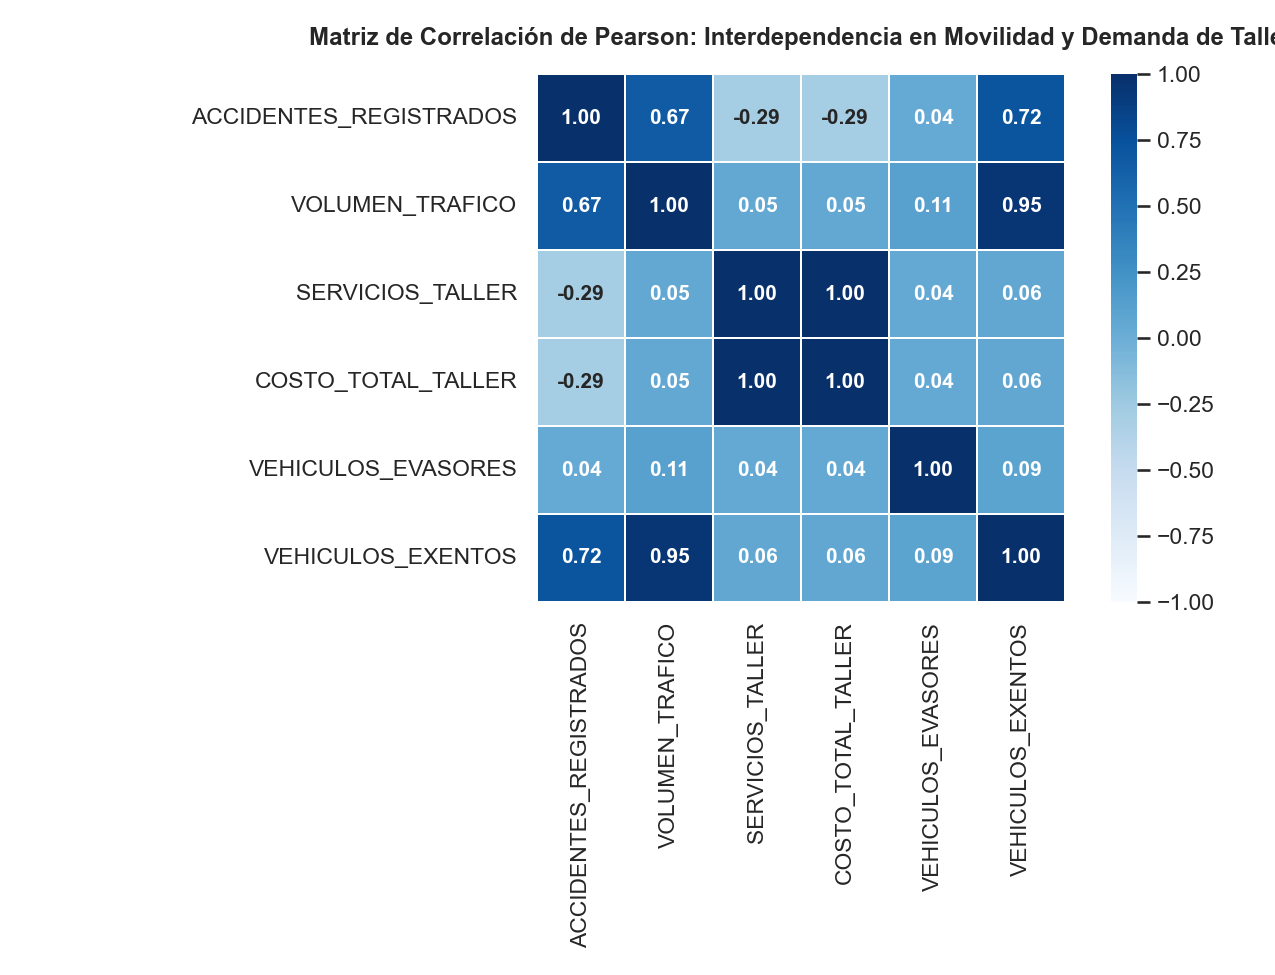

In [9]:
display(Image(filename="figuras/fig_heatmap_correlaciones.png"))


Interpretación: La relación más alta de la matriz presentada es entre servicios de taller y costo total del taller (r = 0,9854); tráfico y accidentes también muestran una asociación fuerte (r = 0,8241).

### 8.6 Figura 6: Matriz de Dispersión Multivariada (Pairplot con KDE)


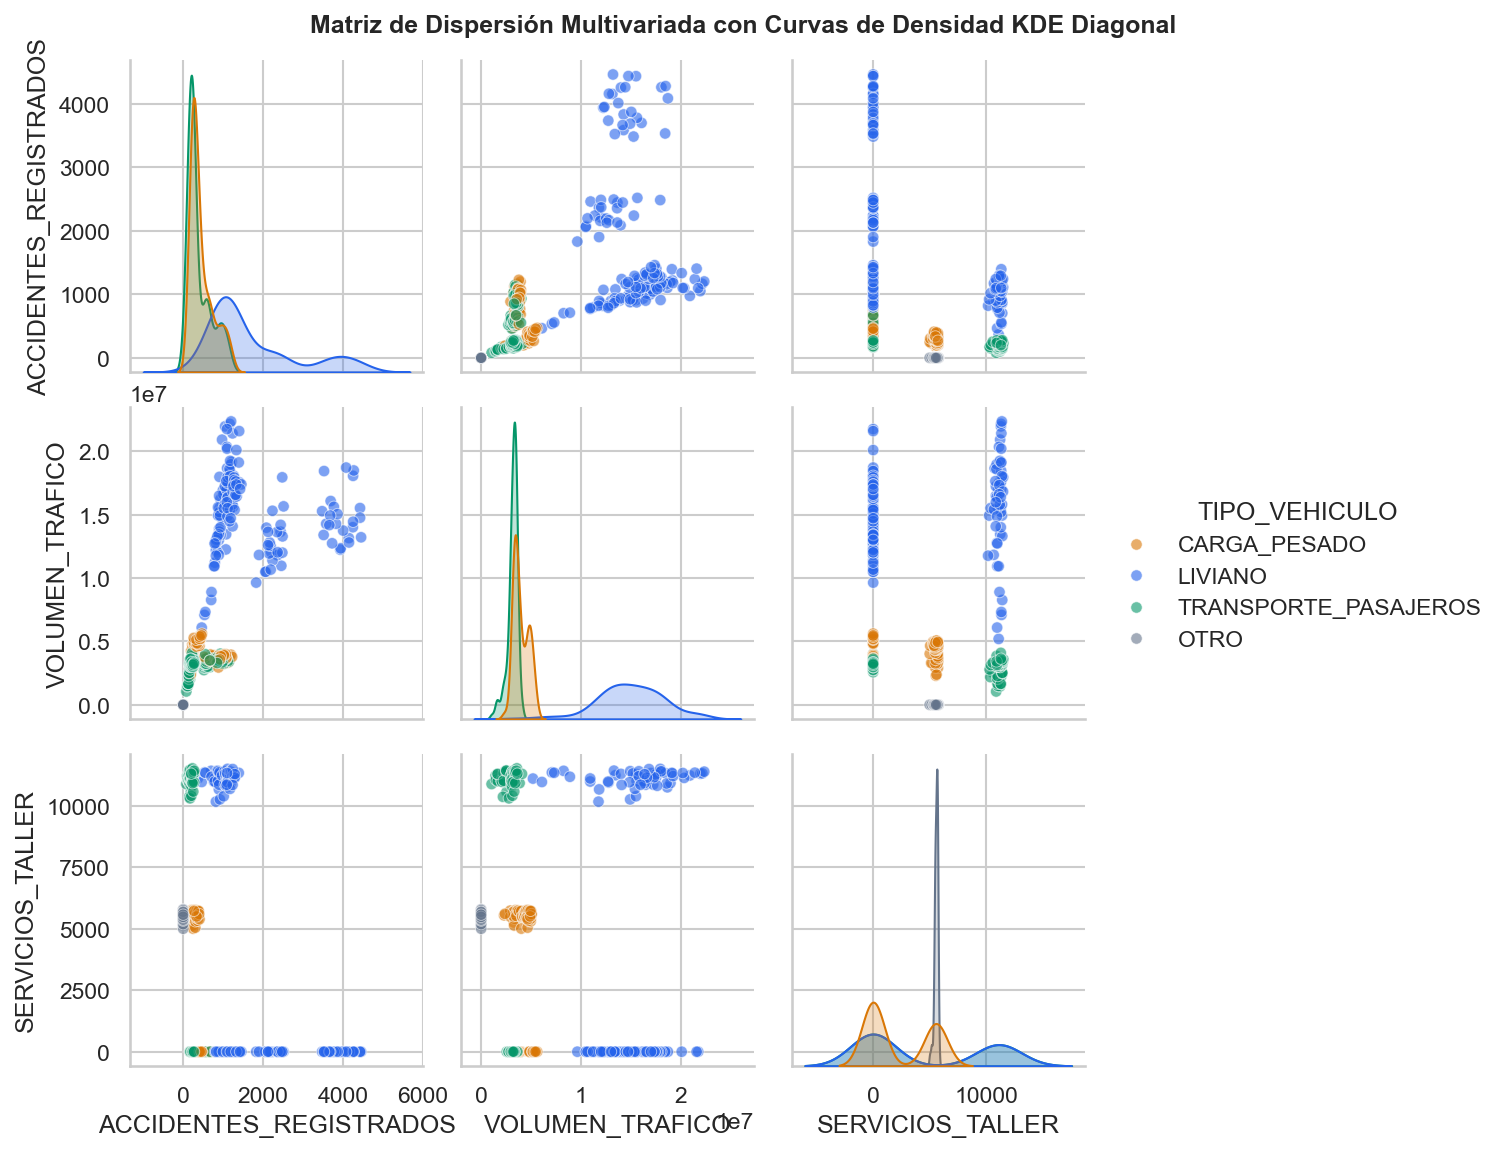

In [10]:
display(Image(filename="figuras/fig_matriz_dispersion.png"))


Interpretación: Permite explorar conjuntamente las distribuciones y relaciones entre variables seleccionadas y comparar patrones entre tipologías vehiculares.

### 8.7 Figura 7: Boxplot de Costo de Taller por Tipología


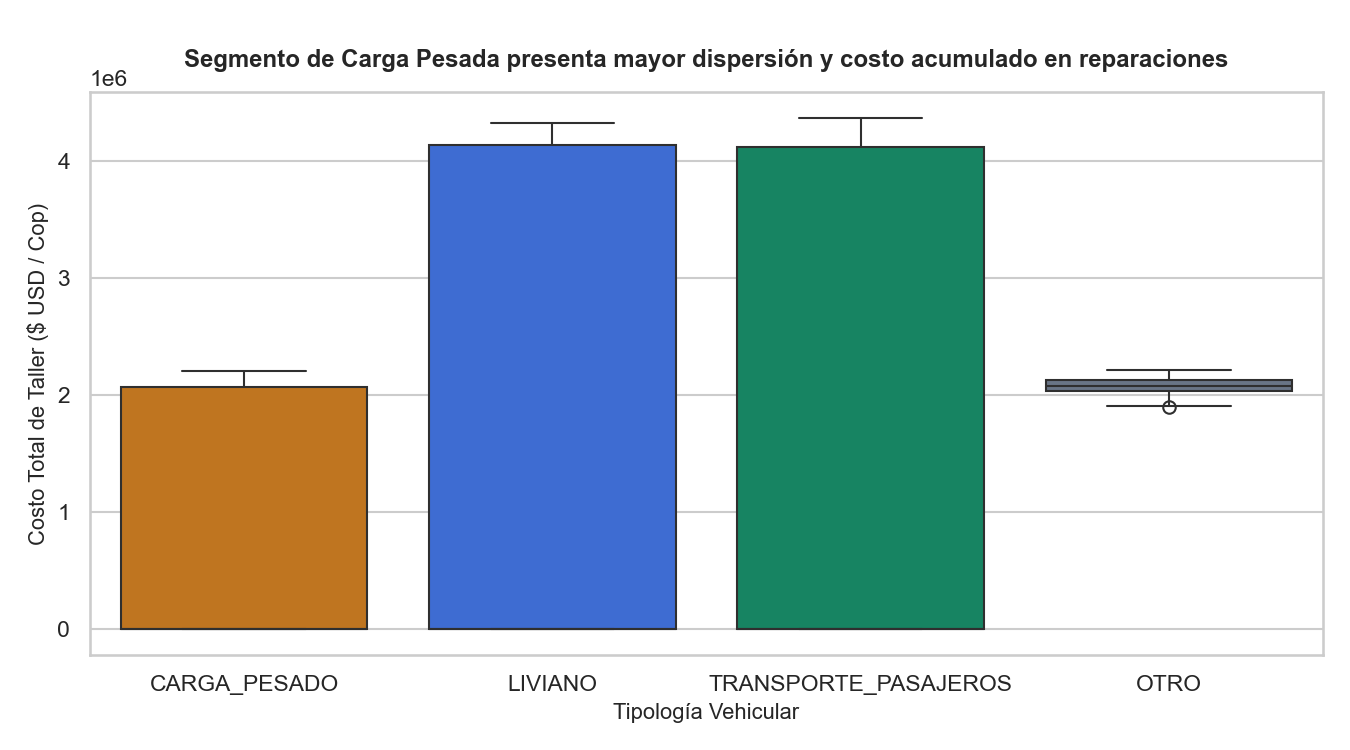

In [11]:
display(Image(filename="figuras/fig_box_costo_tipo_vehiculo.png"))


Interpretación: La carga pesada presenta el mayor costo acumulado reportado. La comparación debe considerar también el volumen de cada segmento y la escala de los costos.

### 8.8 Figura 8: Tendencia Multianual de Siniestralidad Vial


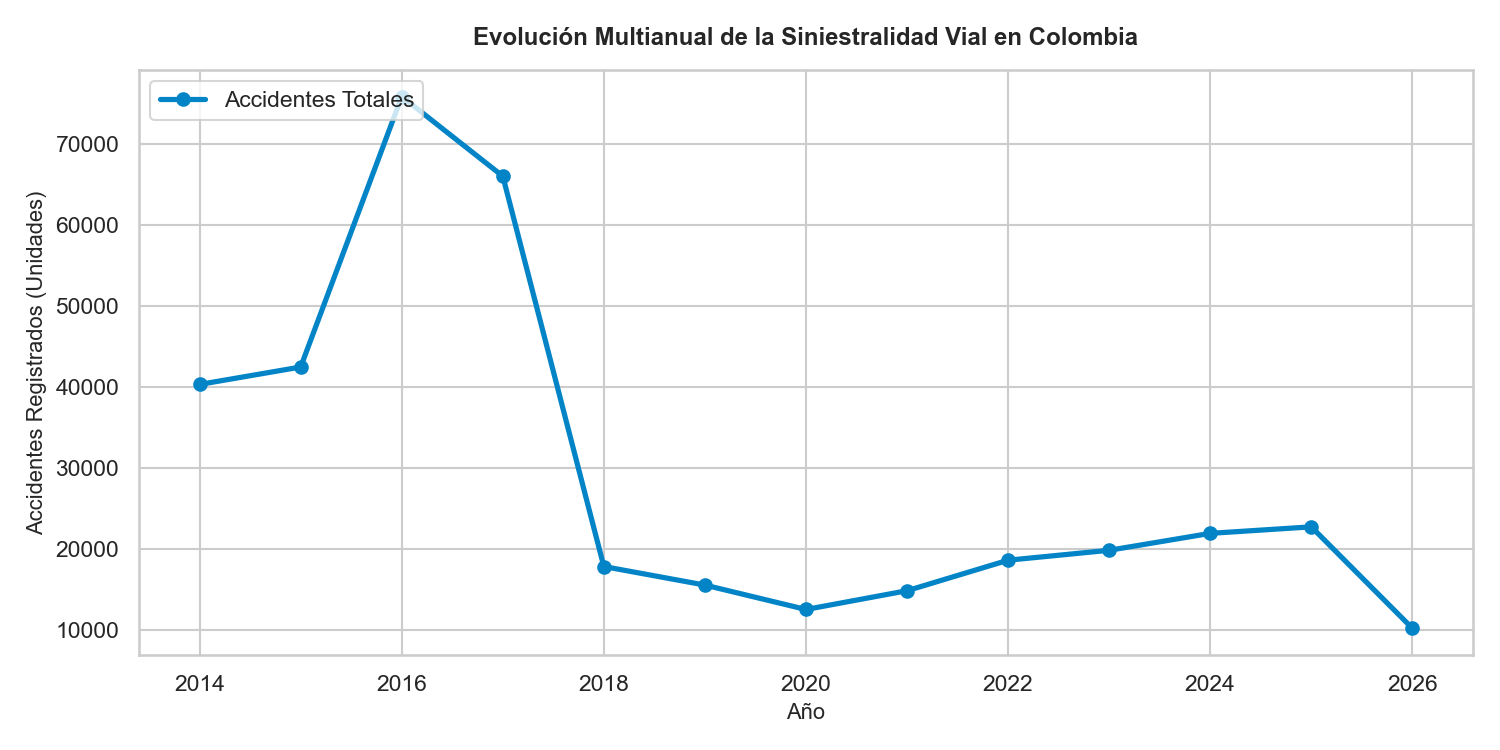

In [12]:
display(Image(filename="figuras/fig_tendencia_temporal_siniestralidad.png"))


Interpretación: La figura permite revisar cambios en el tiempo, incluida la caída señalada para 2020 y la recuperación posterior descrita en el material suministrado.

## 9. Hallazgos Accionables y Recomendaciones


In [13]:
eda.imprimir_resumen_ejecutivo()


RESUMEN EJECUTIVO · HALLAZGOS Y ACCIONES DE NEGOCIO (AUTOGEST)

1. Hiperasimetría y Concentración Temporal de Siniestros Viales.
  • Evidencia: La media de accidentalidad supera a la mediana debido a picos estacionales críticos.
  • Acción   : Diseñar calendarios de refuerzo preventivo en corredores viales durante temporadas de alta congestión.

2. Correlación Directa entre Aforo de Tráfico y Desgaste Mecánico.
  • Evidencia: Existe fuerte asociación lineal (Pearson r > 0.6) entre el flujo de vehículos y la demanda de taller.
  • Acción   : Planificar capacidad de respuesta en talleres y disponibilidad de grúas en función de aforos proyectados.

3. Sobrecosto Crítico en Flota de Carga Pesada.
  • Evidencia: El segmento de camiones y carga pesada triplica la dispersión y media en costo de repuestos y reparaciones.
  • Acción   : Implementar telemetría y mantenimiento preventivo predictivo específico para vehículos de carga pesada.
